In [1]:
%pip install -q qiskit matplotlib pylatexenc

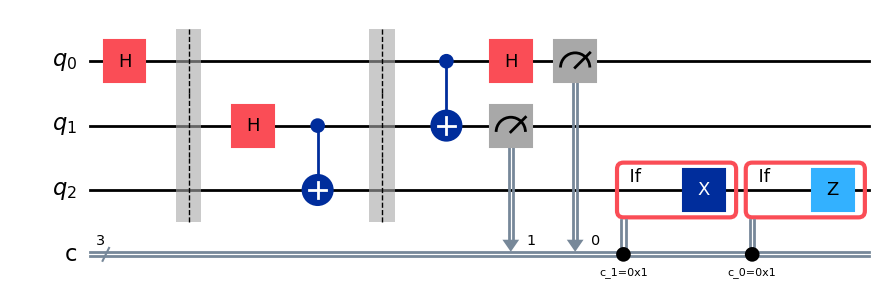

In [5]:
from qiskit import QuantumCircuit

# 1. Tres qubits y tres bits clásicos.
qc = QuantumCircuit(3, 3)

# 2. Estado de prueba que queremos teleportar: |+>.
qc.h(0)

qc.barrier()

# 3. Par entrelazado entre Alice y Bob.
qc.h(1)
qc.cx(1, 2)

qc.barrier()

# 4. Operaciones de Alice.
qc.cx(0, 1)
qc.h(0)

# 5. Mediciones de Alice.
qc.measure(0, 0)
qc.measure(1, 1)

# 6. Correcciones de Bob según los resultados de Alice.
# Si c1 = 1, aplica X sobre q2.
with qc.if_test((qc.clbits[1], 1)):
    qc.x(2)

# Si c0 = 1, aplica Z sobre q2.
with qc.if_test((qc.clbits[0], 1)):
    qc.z(2)

# 7. Dibujamos el circuito.
qc.draw("mpl", fold=-1)

In [6]:
%pip install -q qiskit-aer

In [7]:
from qiskit import transpile
from qiskit_aer import AerSimulator

# Copiamos el circuito para agregar la verificación.
qc_prueba = qc.copy()

qc_prueba.barrier()

# Si Bob recuperó |+>, esta H lo transforma en |0>.
qc_prueba.h(2)

# Medimos q2 y guardamos el resultado en c2.
qc_prueba.measure(2, 2)

# Creamos un simulador ideal, sin ruido.
simulador = AerSimulator()

# Adaptamos el circuito al simulador.
compilado = transpile(
    qc_prueba,
    simulador,
    seed_transpiler=2026
)

# Ejecutamos el circuito completo 1024 veces.
shots = 1024

resultado = simulador.run(
    compilado,
    shots=shots,
    seed_simulator=2026
).result()

conteos = resultado.get_counts()

# Qiskit muestra los bits en el orden c2 c1 c0.
# El primer carácter corresponde a la medición de Bob.
ceros_bob = sum(
    cantidad
    for bits, cantidad in conteos.items()
    if bits[0] == "0"
)

print("Conteos en orden c2 c1 c0:")
print(conteos)

print("\nEjecuciones:", shots)
print("Veces que Bob obtuvo 0 tras la H:", ceros_bob)
print(f"Porcentaje de verificación: {100 * ceros_bob / shots:.2f}%")

Conteos en orden c2 c1 c0:
{'011': 261, '001': 246, '000': 272, '010': 245}

Ejecuciones: 1024
Veces que Bob obtuvo 0 tras la H: 1024
Porcentaje de verificación: 100.00%


In [8]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator


# 1. Definimos cómo preparar cada estado desde |0>.
def preparar_estado(estado):

    preparacion = QuantumCircuit(1)

    if estado == "1":
        preparacion.x(0)

    elif estado == "+":
        preparacion.h(0)

    elif estado == "-":
        preparacion.h(0)
        preparacion.z(0)

    elif estado == "+i":
        preparacion.h(0)
        preparacion.s(0)

    elif estado == "-i":
        preparacion.h(0)
        preparacion.sdg(0)

    elif estado != "0":
        raise ValueError("Estado no reconocido.")

    # Para el estado "0" no aplicamos ninguna compuerta.
    return preparacion


# 2. Construimos la teleportación y su verificación.
def crear_circuito(estado):

    preparacion = preparar_estado(estado)
    circuito = QuantumCircuit(3, 3)

    # Preparamos el estado de entrada en q0.
    circuito.compose(
        preparacion,
        qubits=[0],
        inplace=True
    )

    circuito.barrier()

    # Par entrelazado.
    circuito.h(1)
    circuito.cx(1, 2)

    circuito.barrier()

    # Operaciones y mediciones de Alice.
    circuito.cx(0, 1)
    circuito.h(0)

    circuito.measure(0, 0)
    circuito.measure(1, 1)

    # Correcciones de Bob.
    with circuito.if_test((circuito.clbits[1], 1)):
        circuito.x(2)

    with circuito.if_test((circuito.clbits[0], 1)):
        circuito.z(2)

    circuito.barrier()

    # Verificación: deshacemos la preparación sobre q2.
    circuito.compose(
        preparacion.inverse(),
        qubits=[2],
        inplace=True
    )

    circuito.measure(2, 2)

    return circuito


# 3. Configuración de las pruebas.
estados = ["0", "1", "+", "-", "+i", "-i"]
shots = 1024

simulador = AerSimulator()
resultados_teleportacion = []

print("Estado | Verificaciones correctas | Fidelidad estimada")

# 4. Ejecutamos una prueba para cada estado.
for i, estado in enumerate(estados):

    circuito = crear_circuito(estado)

    compilado = transpile(
        circuito,
        simulador,
        seed_transpiler=2026
    )

    resultado = simulador.run(
        compilado,
        shots=shots,
        seed_simulator=2026 + i
    ).result()

    conteos = resultado.get_counts()

    # Orden de los resultados: c2 c1 c0.
    exitos = sum(
        cantidad
        for bits, cantidad in conteos.items()
        if bits[0] == "0"
    )

    fidelidad = exitos / shots

    resultados_teleportacion.append({
        "estado": estado,
        "shots": shots,
        "exitos": exitos,
        "fidelidad": fidelidad,
        "conteos": conteos
    })

    print(
        f"{estado:>6} | "
        f"{exitos:>10}/{shots:<10} | "
        f"{fidelidad:.4f}"
    )

# 5. Promedio de las fidelidades.
fidelidad_promedio = sum(
    fila["fidelidad"]
    for fila in resultados_teleportacion
) / len(resultados_teleportacion)

print(f"\nFidelidad promedio: {fidelidad_promedio:.4f}")

Estado | Verificaciones correctas | Fidelidad estimada
     0 |       1024/1024       | 1.0000
     1 |       1024/1024       | 1.0000
     + |       1024/1024       | 1.0000
     - |       1024/1024       | 1.0000
    +i |       1024/1024       | 1.0000
    -i |       1024/1024       | 1.0000

Fidelidad promedio: 1.0000


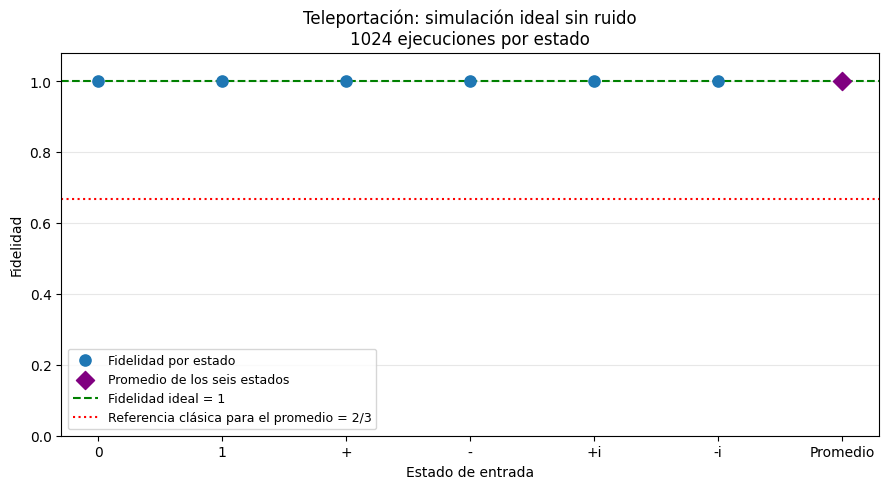

Archivos guardados:
teleportacion_fidelidades_simuladas.csv
teleportacion_conteos_simulados.json
teleportacion_fidelidades_simuladas.png


In [9]:
import csv
import json
import matplotlib.pyplot as plt

# 1. Guardamos el resumen de fidelidades en CSV.
archivo_csv = "teleportacion_fidelidades_simuladas.csv"

with open(
    archivo_csv,
    mode="w",
    newline="",
    encoding="utf-8"
) as archivo:

    escritor = csv.writer(archivo)

    escritor.writerow([
        "estado",
        "ejecuciones",
        "verificaciones_correctas",
        "fidelidad_estimada"
    ])

    for fila in resultados_teleportacion:
        escritor.writerow([
            fila["estado"],
            fila["shots"],
            fila["exitos"],
            fila["fidelidad"]
        ])


# 2. Guardamos también los conteos completos.
archivo_json = "teleportacion_conteos_simulados.json"

datos = {
    "tipo": "simulacion_ideal_sin_ruido",
    "orden_bits": "c2 c1 c0",
    "verificacion": (
        "c2 = 0 despues de aplicar la inversa "
        "de la preparacion al qubit de Bob"
    ),
    "resultados": resultados_teleportacion,
    "fidelidad_promedio": fidelidad_promedio
}

with open(
    archivo_json,
    mode="w",
    encoding="utf-8"
) as archivo:

    json.dump(
        datos,
        archivo,
        indent=4,
        ensure_ascii=False
    )


# 3. Extraemos los datos para la gráfica.
nombres = [
    fila["estado"]
    for fila in resultados_teleportacion
]

fidelidades = [
    fila["fidelidad"]
    for fila in resultados_teleportacion
]

posiciones = list(range(len(nombres)))
posicion_promedio = len(nombres)


# 4. Dibujamos las fidelidades de los seis estados.
plt.figure(figsize=(9, 5))

plt.scatter(
    posiciones,
    fidelidades,
    s=65,
    label="Fidelidad por estado",
    zorder=3
)

# El promedio se muestra como un punto adicional.
plt.scatter(
    posicion_promedio,
    fidelidad_promedio,
    marker="D",
    s=85,
    color="purple",
    label="Promedio de los seis estados",
    zorder=4
)

plt.axhline(
    1,
    color="green",
    linestyle="--",
    label="Fidelidad ideal = 1"
)

plt.axhline(
    2 / 3,
    color="red",
    linestyle=":",
    label="Referencia clásica para el promedio = 2/3"
)

plt.xticks(
    posiciones + [posicion_promedio],
    nombres + ["Promedio"]
)

plt.xlabel("Estado de entrada")
plt.ylabel("Fidelidad")
plt.ylim(0, 1.08)

plt.title(
    "Teleportación: simulación ideal sin ruido\n"
    f"{resultados_teleportacion[0]['shots']} ejecuciones por estado"
)

plt.grid(axis="y", alpha=0.3)
plt.legend(fontsize=9)
plt.tight_layout()

archivo_figura = "teleportacion_fidelidades_simuladas.png"

plt.savefig(archivo_figura, dpi=300)
plt.show()

print("Archivos guardados:")
print(archivo_csv)
print(archivo_json)
print(archivo_figura)

In [14]:
files.download("teleportacion_fidelidades_simuladas.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
from google.colab import files

files.download("teleportacion_fidelidades_simuladas.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
files.download("teleportacion_conteos_simulados.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>